# Forecasting Baselines

## 1. Load and Validate Hourly Data

Establish simple, reproducible benchmarks for forecasting
electricity demand over the next 24 hours.

Initial approach:
- Use chronological data splits.
- Preserve missing observations.
- Evaluate against daily and weekly seasonal-naive forecasts.
- Prevent future information from entering predictions.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_parquet(
    PROJECT_ROOT / "data/processed/hourly_power.parquet"
)

df = df.sort_values("timestamp").set_index("timestamp")

df.head()

,mean_power_kw,valid_minutes
timestamp,,
2006-12-16 17:00:00,4.222889,36
2006-12-16 18:00:00,3.632200,60
2006-12-16 19:00:00,3.400233,60
2006-12-16 20:00:00,3.268567,60
2006-12-16 21:00:00,3.056467,60


In [2]:
# Preserve the full hourly timeline.
power = df["mean_power_kw"].where(
    df["valid_minutes"] == 60
)

print("Total hours:", len(power))
print("Usable hours:", power.notna().sum())
print("Unavailable hours:", power.isna().sum())

Total hours: 34589
Usable hours: 34085
Unavailable hours: 504


## 2. Seasonal-Naive Forecasts

In [4]:
baseline_df = pd.DataFrame({
    "actual": power,
    "daily_naive": power.shift(24),
    "weekly_naive": power.shift(168),
})

baseline_df.head(30)

,actual,daily_naive,weekly_naive
timestamp,,,
2006-12-16 17:00:00,NaN,NaN,NaN
2006-12-16 18:00:00,3.632200,NaN,NaN
2006-12-16 19:00:00,3.400233,NaN,NaN
2006-12-16 20:00:00,3.268567,NaN,NaN
2006-12-16 21:00:00,3.056467,NaN,NaN
2006-12-16 22:00:00,2.200133,NaN,NaN
2006-12-16 23:00:00,2.061600,NaN,NaN
2006-12-17 00:00:00,1.882467,NaN,NaN
2006-12-17 01:00:00,3.349400,NaN,NaN


In [5]:
print("Total hourly observations:", len(baseline_df))

print(
    "Valid daily baseline comparisons:",
    baseline_df[["actual", "daily_naive"]].dropna().shape[0]
)

print(
    "Valid weekly baseline comparisons:",
    baseline_df[["actual", "weekly_naive"]].dropna().shape[0]
)

print(
    "Valid comparisons for both baselines:",
    baseline_df.dropna().shape[0]
)

Total hourly observations: 34589
Valid daily baseline comparisons: 33833
Valid weekly baseline comparisons: 33417
Valid comparisons for both baselines: 33190


In [6]:
train = baseline_df.loc[: "2008-12-31 23:00"]
val = baseline_df.loc["2009-01-01":"2009-12-31 23:00"]
test = baseline_df.loc["2010-01-01":]

print("Training:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

Training: 17911
Validation: 8760
Test: 7918


In [7]:
for name, split in [
    ("Train", train),
    ("Validation", val),
    ("Test", test),
]:
    print(
        name,
        "| Start:", split.index.min(),
        "| End:", split.index.max(),
        "| Rows:", len(split),
    )

Train | Start: 2006-12-16 17:00:00 | End: 2008-12-31 23:00:00 | Rows: 17911
Validation | Start: 2009-01-01 00:00:00 | End: 2009-12-31 23:00:00 | Rows: 8760
Test | Start: 2010-01-01 00:00:00 | End: 2010-11-26 21:00:00 | Rows: 7918


## 3. Baseline Evaluation

Compare daily and weekly seasonal-naive forecasts
using MAE and RMSE on identical validation timestamps.

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Compare both baselines on the same valid timestamps
val_clean = val.dropna(
    subset=["actual", "daily_naive", "weekly_naive"]
)

results = []

for model in ["daily_naive", "weekly_naive"]:
    mae = mean_absolute_error(
        val_clean["actual"],
        val_clean[model]
    )

    rmse = np.sqrt(
        mean_squared_error(
            val_clean["actual"],
            val_clean[model]
        )
    )

    results.append({
        "model": model,
        "MAE_kW": mae,
        "RMSE_kW": rmse
    })

results_df = pd.DataFrame(results)
results_df

,model,MAE_kW,RMSE_kW
0,daily_naive,0.608949,0.899224
1,weekly_naive,0.565123,0.844744


## 4. Visualize Baseline Predictions

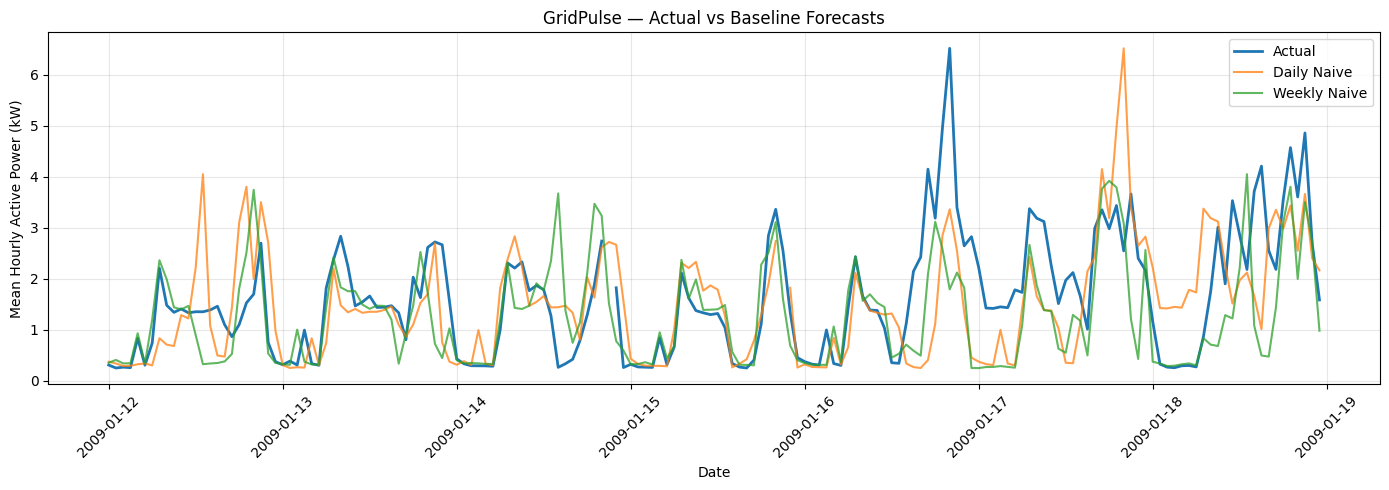

In [10]:
# Select one week of validation data
sample = val.loc["2009-01-12":"2009-01-18"]

plt.figure(figsize=(14, 5))

plt.plot(
    sample.index,
    sample["actual"],
    label="Actual",
    linewidth=2
)

plt.plot(
    sample.index,
    sample["daily_naive"],
    label="Daily Naive",
    alpha=0.75
)

plt.plot(
    sample.index,
    sample["weekly_naive"],
    label="Weekly Naive",
    alpha=0.75
)

plt.title("GridPulse — Actual vs Baseline Forecasts")
plt.xlabel("Date")
plt.ylabel("Mean Hourly Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Baseline Forecast Observations

- Both daily and weekly seasonal-naive models capture recurring
  daily electricity consumption patterns.
- Both struggle with sudden, unusually high consumption peaks.
- The January 16 spike (~6.5 kW) is substantially underestimated
  by both baselines.
- The daily baseline repeats this spike on January 17,
  creating a large overprediction.
- Weekly seasonal naive performs better overall on validation,
  suggesting that weekly consumption routines contain useful
  forecasting information.

**Implication:** Future models should be evaluated not only
on average forecasting error, but also on their ability to
anticipate high-demand periods.

## 5. Forecasting Error by Hour of Day

Investigate whether daily and weekly seasonal-naive models
make larger forecasting errors during particular hours.

In [11]:
# Use the same clean validation data from Step 10
hourly_errors = val_clean.copy()

# Extract hour of day from the timestamp index
hourly_errors["hour"] = hourly_errors.index.hour

# Calculate absolute forecasting errors
hourly_errors["daily_error"] = (
    hourly_errors["actual"] - hourly_errors["daily_naive"]
).abs()

hourly_errors["weekly_error"] = (
    hourly_errors["actual"] - hourly_errors["weekly_naive"]
).abs()

# Average the errors for each hour
error_by_hour = hourly_errors.groupby("hour")[
    ["daily_error", "weekly_error"]
].mean()

error_by_hour.head()

,daily_error,weekly_error
hour,,
0,0.408798,0.343522
1,0.302714,0.293189
2,0.243054,0.231446
3,0.217646,0.222069
4,0.227625,0.248950


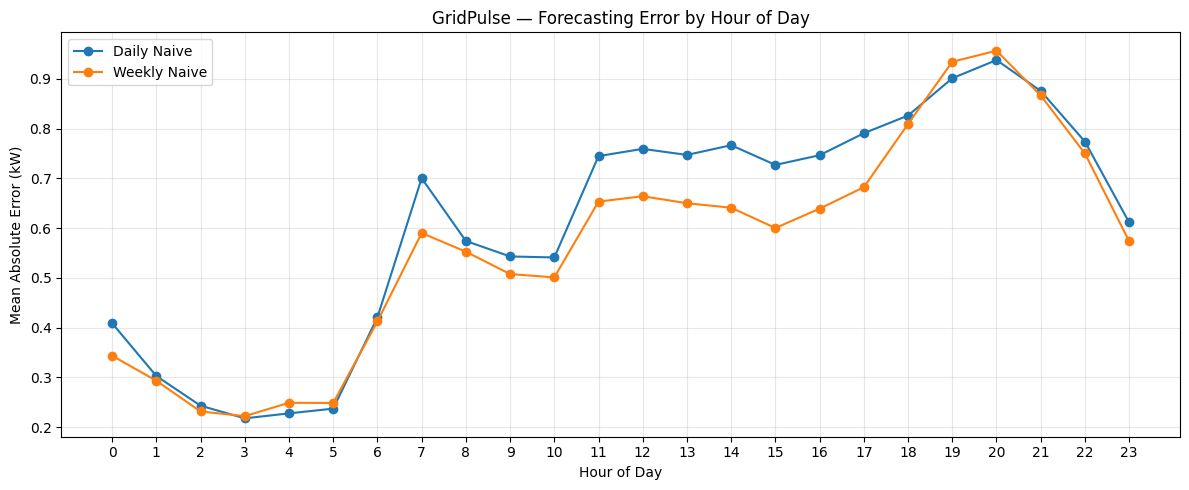

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    error_by_hour.index,
    error_by_hour["daily_error"],
    marker="o",
    label="Daily Naive"
)

plt.plot(
    error_by_hour.index,
    error_by_hour["weekly_error"],
    marker="o",
    label="Weekly Naive"
)

plt.title("GridPulse — Forecasting Error by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Absolute Error (kW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Forecast Error by Hour — Findings

- Forecasting errors are lowest overnight, especially around 3 AM.
- Both baselines experience their highest errors around 8 PM.
- The weekly baseline performs substantially better during
  afternoon hours, particularly around 11 AM–4 PM.
- Weekly naive is not universally better: daily naive has
  slightly lower errors during portions of the evening peak.
- High-demand hours appear more difficult to forecast
  accurately in absolute kW.

**Implication:** Future forecasting models should incorporate
hour-of-day, day-of-week, and historical lag features.
Evaluate evening peak performance separately from overall MAE.

## 6. Forecasting Error by Season

Compare daily and weekly seasonal-naive forecasting
performance across winter, spring, summer, and fall.

In [13]:
seasonal_errors = val_clean.copy()

# Extract the month from the timestamp
seasonal_errors["month"] = seasonal_errors.index.month

# Map each month to a season
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Fall", 10: "Fall", 11: "Fall"
}

seasonal_errors["season"] = (
    seasonal_errors["month"].map(season_map)
)

# Calculate absolute forecasting errors
seasonal_errors["daily_error"] = (
    seasonal_errors["actual"] -
    seasonal_errors["daily_naive"]
).abs()

seasonal_errors["weekly_error"] = (
    seasonal_errors["actual"] -
    seasonal_errors["weekly_naive"]
).abs()

# Average error by season
error_by_season = seasonal_errors.groupby("season")[
    ["daily_error", "weekly_error"]
].mean()

# Arrange seasons chronologically
error_by_season = error_by_season.reindex(
    ["Winter", "Spring", "Summer", "Fall"]
)

error_by_season

,daily_error,weekly_error
season,,
Winter,0.769828,0.725224
Spring,0.594791,0.568077
Summer,0.432335,0.447759
Fall,0.629092,0.513561


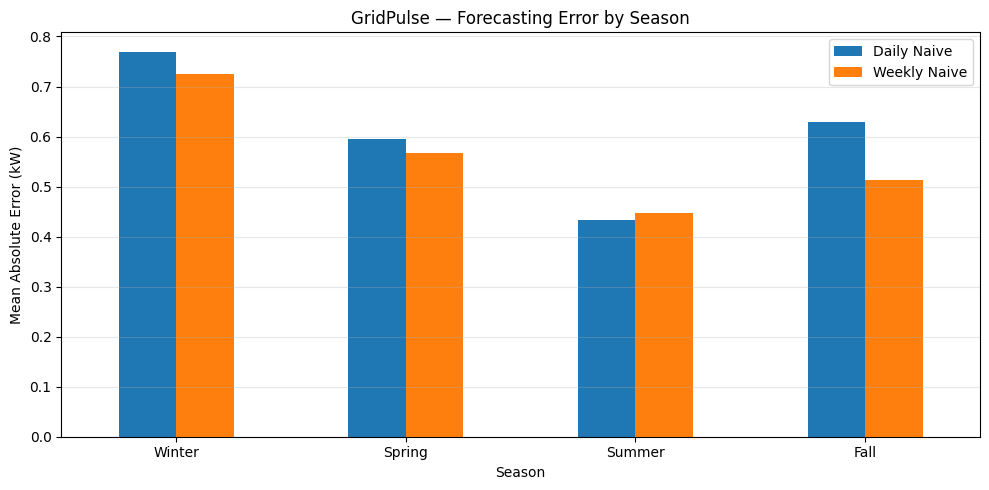

In [14]:
ax = error_by_season.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("GridPulse — Forecasting Error by Season")
plt.xlabel("Season")
plt.ylabel("Mean Absolute Error (kW)")
plt.legend(["Daily Naive", "Weekly Naive"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Seasonal Forecast Error — Findings

- Winter has the highest forecasting errors for both seasonal-naive baselines.
- Summer has the lowest absolute forecasting errors.
- Weekly naive outperforms daily naive in winter, spring, and fall.
- Daily naive slightly outperforms weekly naive during summer.
- Fall shows the largest advantage for weekly naive.

**Interpretation:** Electricity forecasting accuracy varies by season, and no single baseline is best across every season.

**Implication:** Future models should incorporate calendar features such as month, season, hour of day, and day of week, alongside historical electricity measurements.

These results are based on 2009 validation data and should be checked against additional periods before drawing general conclusions.